In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".08"
import numpy as np
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer
from skophys.sm import NNCCA, NNSM
from skophys.datasets import ARProcessMovie
from sklearn.metrics.pairwise import cosine_similarity
from skimage.transform import downscale_local_mean
from ipywidgets import HBox, VBox
import fastplotlib as fpl
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
import seaborn as sns
from itertools import product

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
%matplotlib inline

In [3]:
locs = np.array([
    [0, 0],
    [2, 0]
])

ar_model = ARProcessMovie(
    n_timepoints=1000,
    n_components=2,
    ar_noise_sigma=0.1,
    obs_noise_sigma=0.3,
    movie_dims=(10, 15),
    component_locs=locs,
    firing_probability=0.02
)

movie = ar_model.movie

In [4]:
movie_mean = movie.mean(axis=0)

In [5]:
iw = fpl.ImageWidget(ar_model.movie, cmap="viridis", figure_kwargs={"size": (500, 500)})

fig_traces = fpl.Figure(size=(900, 500))

traces_lines = fig_traces[0, 0].add_line_collection(ar_model.traces, colors=["b", "r"])

selector = traces_lines[0].add_linear_selector()

def update_time_index(ev: dict | fpl.GraphicFeatureEvent):
    if isinstance(ev, dict):
        index = ev["t"]
    else:
        index = ev.get_selected_index()

    selector.selection = index
    iw.current_index = {"t": index}

selector.add_event_handler(update_time_index, "selection")
iw.add_event_handler(update_time_index)

HBox([iw.show(), fig_traces.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [32]:
model = NNCCA(lag=1, lag_step=1)

In [33]:
model.pre_initialize(movie, max_k=2)

creating H
Whitening H
computing covariance
estimating k
performing nnSVD


In [34]:
model._X_init.shape

(150, 1000)

In [35]:
model.pre_init_arrays.P.shape

(150, 999)

In [36]:
model.pre_init_arrays.Y

array([[6.70887522e-03, 7.11867174e-03, 4.50931327e-03, ...,
        6.63492330e-03, 1.63157845e-03, 9.37795802e-04],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 6.54372113e-05]])

In [37]:
err_log, Ys, Ws = model.initialize(max_iter=5_000, keep_iteration_results=True, eta=0.1)

 13%|██████████████▉                                                                                                       | 632/5000 [00:00<00:05, 770.73it/s]


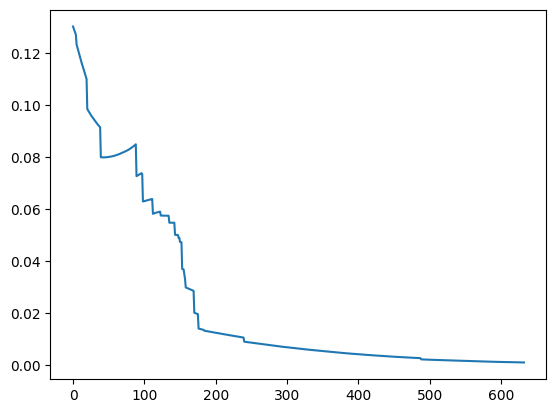

In [38]:
plt.plot(err_log)

<Axes: >

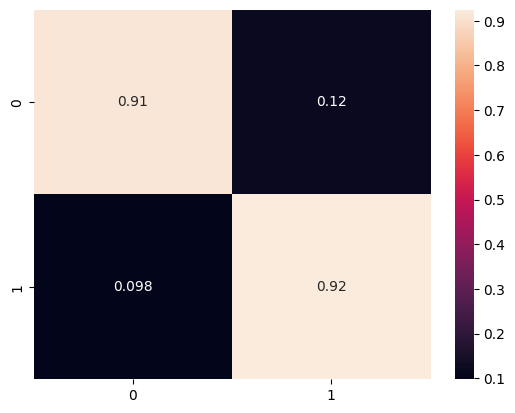

In [39]:
cos_sim = cosine_similarity(ar_model.traces[:, -model.init_arrays.Y.shape[1]:], model.init_arrays.Y)

sns.heatmap(cos_sim, annot=True)

<Axes: >

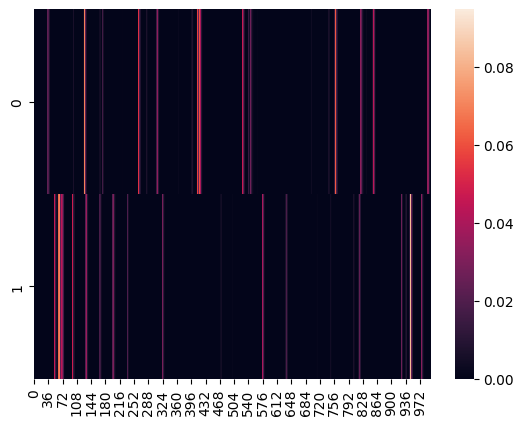

In [40]:
sns.heatmap(model.init_arrays.Y)

RFBOutputContext()

JupyterRenderCanvas(css_height='500.0px', css_width='1500.0px')
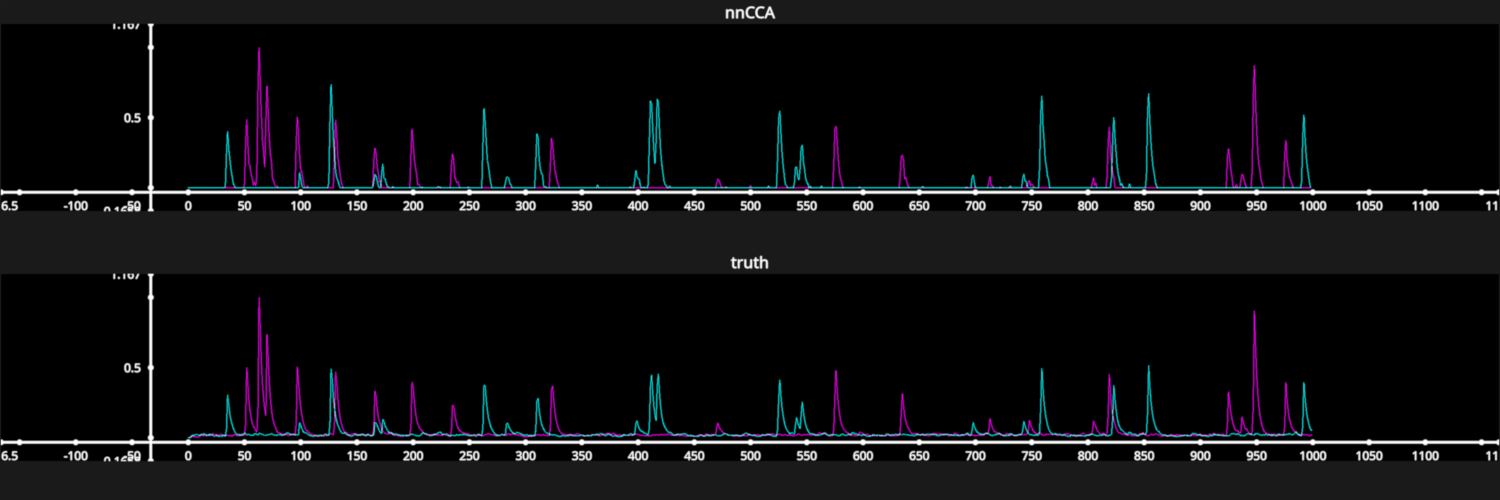

In [47]:
fig = fpl.Figure(shape=(2, 1), names=["nnCCA", "truth"], controller_ids="sync", size=(1500, 500))

fig[0, 0].add_line_collection(model.init_arrays.Y / model.init_arrays.Y.max(), alpha=0.5, colors=["c", "m"], thickness=1)
fig[1, 0].add_line_collection(ar_model.traces / ar_model.traces.max(), alpha=0.5, colors=["c", "m"], thickness=1)

fig.show(maintain_aspect=False)

In [41]:
model.lag_slices

[slice(0, 150, None), slice(150, 300, None)]

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
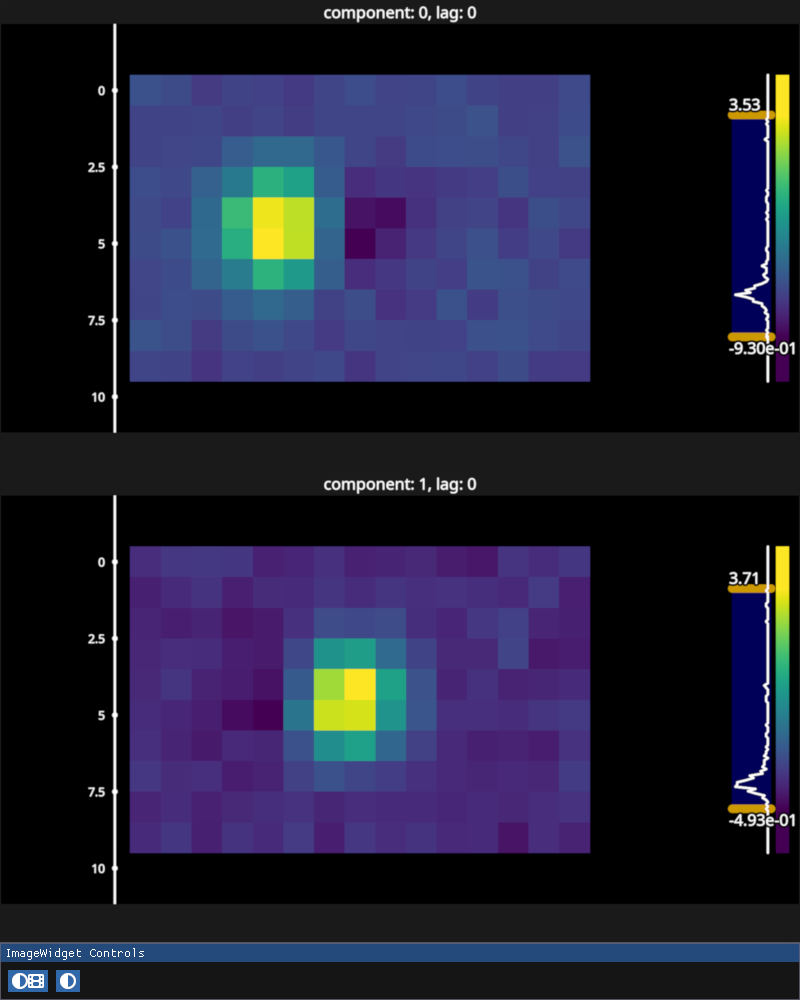

In [42]:
images, titles = list(), list(),
for k_i, l_i in product(range(model.init_arrays.k), range(model.lag)):
    images.append(model.unvec.transform(model.init_arrays.W[k_i, model.lag_slices[l_i]].T))
    titles.append(f"component: {k_i}, lag: {l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(model.init_arrays.k, model.lag),
    figure_kwargs={"size": (800, 1000)},
)

# for g in iw_W.managed_graphics:
#     g.vmin = 0

iw_W.show()